<a href="https://colab.research.google.com/github/shahbazmaryam25/Data-Science-and-Generative-AI/blob/main/week_5_5_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving credit_data_final.csv to credit_data_final.csv


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('credit_data_final.csv')

y_value = df['class'] # set the y
y_values = np.ravel(y_value) # change to an array (list)

x_values = df.drop('class', axis=1) # drop the y from the dataframe

# split data into training and test
from sklearn.model_selection  import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x_values, y_value, test_size = 0.2, random_state=4567, stratify=y_value)

# print the shapes to check everything is OK
print(X_train.shape)
print(X_test.shape)
print(Y_train.shape)
print(Y_test.shape)

(800, 28)
(200, 28)
(800,)
(200,)


In [29]:
# Check for missing values in each column
missing_values = df.isnull().sum()
print("Missing values per column:")
display(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found!")

NameError: name 'df' is not defined

In [3]:
from sklearn.linear_model import LogisticRegression as LogR
from sklearn.ensemble import RandomForestClassifier as RF
from sklearn.ensemble import GradientBoostingClassifier as GBDT
from xgboost import XGBClassifier as XGB
from sklearn.metrics import precision_recall_fscore_support

LogR_algo = LogR()
LogR_model = LogR_algo.fit(X_train, Y_train)

RF_algo = RF()
RF_model = RF_algo.fit(X_train, Y_train)

GBDT_algo = GBDT()
GBDT_model = GBDT_algo.fit(X_train, Y_train)

XGB_algo = XGB()
XGB_model = XGB_algo.fit(X_train, Y_train)

models = [LogR_model, RF_model, GBDT_model, XGB_model]
names = ['Logistic Regression', 'Random Forest', 'GBDT', 'XGBDT']

for i in range(4):
  print(f"Model: {names[i]}")

  # predict based on training data
  predict = models[i].predict(X_train)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(Y_train, predict, average='macro')
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")


Model: Logistic Regression
Macro Precision: 0.695493494128848
Macro Recall: 0.6145833333333334
Macro F1-score: 0.6216980598450139


Model: Random Forest
Macro Precision: 0.999108734402852
Macro Recall: 0.9979166666666667
Macro F1-score: 0.9985101283338207


Model: GBDT
Macro Precision: 0.8988486842105263
Macro Recall: 0.8464285714285714
Macro F1-score: 0.8668188736681888


Model: XGBDT
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0




In [5]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

# we get a load of warnings running the code so will supress them
import warnings
warnings.filterwarnings("ignore")

# create a hyperparameter search function for re-usability
def random_search(algo, hyperparameters, X_train, Y_train):
  # do the search using 5 folds/chunks
  clf = RandomizedSearchCV(algo, hyperparameters, cv=5, random_state=2015,
                          scoring='precision_macro', n_iter=20, refit=True)

  # pass the data to fit/train
  clf.fit(X_train, Y_train)

  return clf.best_params_

# Logistic Regression
LogR_tuned_parameters = {
    'solver': ['liblinear'], # only this one as it does both L1 and L2
    # C is the equivalent of alpha in L1/L2 regression - how much regularisation
    'C': uniform(loc=0.1, scale=19.9),  # Draw from a uniform distribution between 0.1 and 20
    'penalty': ['l1', 'l2', 'elasticnet', None] # elasticnet is a mix of L1 and L2
}

LogR_best_params = random_search(LogR_algo, LogR_tuned_parameters, X_train, Y_train)


# Random Forest
RF_tuned_parameters = {
    'n_estimators': randint(50, 500), # Draw from a uniform distribution between 50 and 500
    'max_depth': randint(2, 7),  # Draw from a uniform distribution between 2 and 7
    'min_samples_split': randint(2, 7),  # Draw from a uniform distribution between 2 and 7
    'max_features': ['sqrt', 'log2', None]
}

RF_best_params = random_search(RF_algo, RF_tuned_parameters, X_train, Y_train)


# GBDT
GBDT_tuned_parameters = {
    'n_estimators': randint(25, 250), # Draw from a uniform distribution between 50 and 500
    'learning_rate': uniform(loc=0.01, scale=4.99),  # Draw from a uniform distribution between 0.01 and 5
    'criterion': ['friedman_mse', 'squared_error'],
    'max_depth': randint(2, 7)  # Draw from a uniform distribution between 2 and 7
}

GBDT_best_params = random_search(GBDT_algo, GBDT_tuned_parameters, X_train, Y_train)


# XGBDT
XGB_tuned_parameters = {
    'n_estimators': randint(25, 250), # Draw from a uniform distribution between 50 and 500
    # eta is learning rate
    'eta': uniform(loc=0.01, scale=4.99),  # Draw from a uniform distribution between 0.01 and 5
    # objective is the same as criterion
    'objective': ['binary:logistic', 'binary:hinge'],
    'max_depth': randint(2, 7)  # Draw from a uniform distribution between 2 and 7
}

XGB_best_params = random_search(XGB_algo, XGB_tuned_parameters, X_train, Y_train)


# Train the models
LogR_algo = LogR(**LogR_best_params)
LogR_model = LogR_algo.fit(X_train, Y_train)

RF_algo = RF(**RF_best_params)
RF_model = RF_algo.fit(X_train, Y_train)

GBDT_algo = GBDT(**GBDT_best_params)
GBDT_model = GBDT_algo.fit(X_train, Y_train)

XGB_algo = XGB(**XGB_best_params)
XGB_model = XGB_algo.fit(X_train, Y_train)


# score the models
models = [LogR_model, RF_model, GBDT_model, XGB_model] # redo this or it uses the old models

for i in range(len(models)): # for every model in the models list
  print(f"Model: {names[i]}")

  # predict based on training data
  predict = models[i].predict(X_train)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(Y_train, predict, average='macro')
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")

Model: Logistic Regression
Macro Precision: 0.6981523631008166
Macro Recall: 0.6211309523809524
Macro F1-score: 0.629761289933129


Model: Random Forest
Macro Precision: 0.8580562659846547
Macro Recall: 0.5375
Macro F1-score: 0.4870550722628496


Model: GBDT
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0


Model: XGBDT
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1-score: 1.0




In [30]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier as GBDT
from sklearn.ensemble import RandomForestClassifier as RF
from sklearn.linear_model import LogisticRegression as LogR
from sklearn.metrics import precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier as XGB

# 1. Load data
df = pd.read_csv("credit_data_final.csv")
y_value = df["class"]
x_values = df.drop("class", axis=1)

# 2. Split data (keeping your exact random_state and stratify)
X_train, X_test, Y_train, Y_test = train_test_split(
    x_values, y_value, test_size=0.2, random_state=4567, stratify=y_value
)

# 3. Train default models
LogR_model = LogR().fit(X_train, Y_train)
RF_model = RF().fit(X_train, Y_train)
GBDT_model = GBDT().fit(X_train, Y_train)
XGB_model = XGB().fit(X_train, Y_train)

models = [LogR_model, RF_model, GBDT_model, XGB_model]
names = ["Logistic Regression", "Random Forest", "GBDT", "XGBDT"]

# 4. Evaluate on TEST data
for i in range(4):
  print(f"Model: {names[i]}")

  # Predict based on TEST data
  predict = models[i].predict(X_test)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(
      Y_test, predict, average="macro"
  )
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")

Model: Logistic Regression
Macro Precision: 0.6270417422867514
Macro Recall: 0.575
Macro F1-score: 0.5736840203764587


Model: Random Forest
Macro Precision: 0.7090715804394048
Macro Recall: 0.6404761904761904
Macro F1-score: 0.6523432067862607


Model: GBDT
Macro Precision: 0.6958910654562829
Macro Recall: 0.6464285714285715
Macro F1-score: 0.6577066344508204


Model: XGBDT
Macro Precision: 0.7138157894736843
Macro Recall: 0.6857142857142857
Macro F1-score: 0.69558599695586




In [31]:
# Use the tuned models from your hyperparameter search
tuned_models = [LogR_model, RF_model, GBDT_model, XGB_model]
names = ["Logistic Regression", "Random Forest", "GBDT", "XGBDT"]

for i in range(4):
  print(f"Model: {names[i]}")

  # Predict based on TEST data using the TUNED models
  predict = tuned_models[i].predict(X_test)

  # Calculate precision, recall, and F1-score
  precision, recall, f1_score, _ = precision_recall_fscore_support(
      Y_test, predict, average="macro"
  )
  print(f"Macro Precision: {precision}")
  print(f"Macro Recall: {recall}")
  print(f"Macro F1-score: {f1_score}")
  print("\n")

Model: Logistic Regression
Macro Precision: 0.6270417422867514
Macro Recall: 0.575
Macro F1-score: 0.5736840203764587


Model: Random Forest
Macro Precision: 0.7090715804394048
Macro Recall: 0.6404761904761904
Macro F1-score: 0.6523432067862607


Model: GBDT
Macro Precision: 0.6958910654562829
Macro Recall: 0.6464285714285715
Macro F1-score: 0.6577066344508204


Model: XGBDT
Macro Precision: 0.7138157894736843
Macro Recall: 0.6857142857142857
Macro F1-score: 0.69558599695586




Random Forest Confusion Matrix


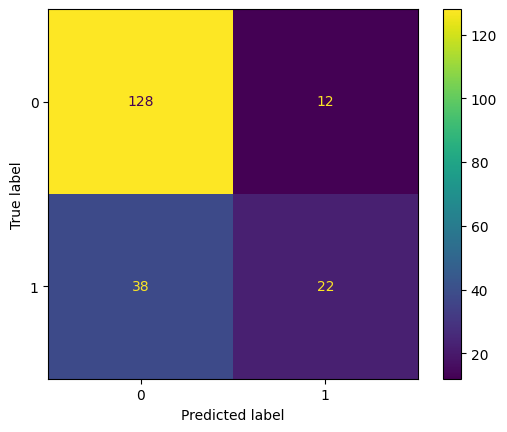

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay as CM

# Random Forest
print("Random Forest Confusion Matrix")
predict = RF_model.predict(X_test)
CM.from_predictions(Y_test, predict)

GBDT Confusion Matrix


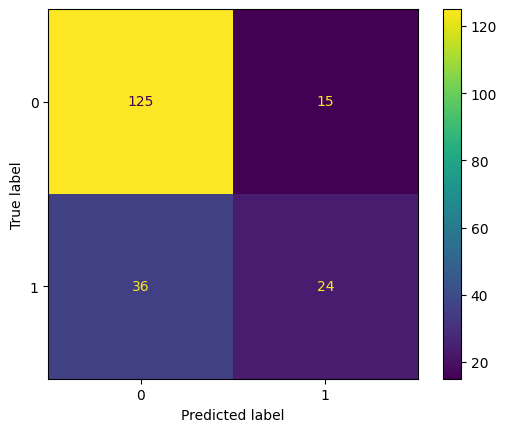

In [33]:
# GBDT
print("GBDT Confusion Matrix")
predict = GBDT_model.predict(X_test)
print(CM.from_predictions(Y_test, predict))